# Population Distribution: Clinton Hill, Prospect Heights & Crown Heights

**Goal:** estimate where people live *inside* each census block group by spreading the 2020 Census count onto MapPLUTO tax lots in proportion to their residential units. The result is a lot-level population map for the study area.

**Study area:** four 2020 Neighborhood Tabulation Areas (NTAs) in Brooklyn:

| NTA code | Neighborhood |
|---|---|
| BK0204 | Clinton Hill |
| BK0801 | Prospect Heights |
| BK0802 | Crown Heights (North) |
| BK0901 | Crown Heights (South) |

**Data sources**

| Data | What it gives us | Source |
|---|---|---|
| 2020 Census DHC, table P1 | Total population per block group (a full count, no margin of error) | `Data_Input/Raw Population/2020_Census_P1/` (downloaded from data.census.gov) |
| 2020 TIGER/Line block groups | Block-group shapes for Brooklyn | Census Bureau, read straight from the web |
| 2020 NTAs | Neighborhood boundaries used to pick the study area | NYC Open Data (`9nt8-h7nd`) |
| MapPLUTO | Tax lots with residential-unit counts (`UnitsRes`) and 2020 census block (`BCTCB2020`) | NYC DCP ArcGIS FeatureServer |

**Steps**

1. Load the P1 population table.
2. Load block-group shapes and attach population.
3. Select the block groups that make up the four NTAs.
4. Map the "even spread" baseline (population spread evenly across each block group).
5. Download MapPLUTO lots for the study area.
6. Build a common block-group ID on the lots.
7. Apportion each block group's population to its lots by residential units.
8. Map population per lot, then as dots.

Everything is projected to **EPSG:2263** (NY State Plane Long Island, US feet), the CRS MapPLUTO uses.

## Setup

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from cdptools import utils

utils.set_axis_off()

# ---- Settings -------------------------------------------------------------
PROJECT = Path("/Users/temp/Documents/GitHub/MappingAffordances")
P1_CSV = PROJECT / "Data_Input/Raw Population/2020_Census_P1/DECENNIALDHC2020.P1-Data.csv"
OUTPUT_DIR = PROJECT / "Data_Output/Population"

# Study area: 2020 NTA codes (change this list to run another area)
STUDY_NTAS = ["BK0204", "BK0801", "BK0802", "BK0901"]
STUDY_NAME = "Clinton Hill, Prospect Heights & Crown Heights"

CRS = 2263              # NY State Plane Long Island (US feet), same as MapPLUTO
BROOKLYN_FIPS = "047"   # Kings County

# MapPLUTO uses a 1-digit borough code; Census uses 3-digit county FIPS codes
BORO_TO_COUNTY = {"1": "061", "2": "005", "3": "047", "4": "081", "5": "085"}

rng = np.random.default_rng(42)  # fixed seed so the dot maps are reproducible

## 1. Load 2020 Census population (table P1)

The CSV from data.census.gov has **two header rows**: row 1 holds the column codes (`GEO_ID`, `P1_001N`) and row 2 holds descriptive labels. `skiprows=[1]` drops the label row.

`GEO_ID` is read as **text** because it is an identifier, not a quantity. Read as a number, any IDs or codes we slice out of it would lose their leading zeros (`"047"` → `47`) and joins would silently fail.

`GEO_ID` looks like `1500000US360470001001`:
- `1500000US` is the Census prefix (`150` = block group level)
- the last **12 digits** are the block-group GEOID: state `36` + county `047` + tract `000100` + block group `1`

We keep those 12 digits as `GEOID`, which is the key used for every join below.

In [2]:
p1 = pd.read_csv(P1_CSV, skiprows=[1], dtype={"GEO_ID": str})
p1 = p1[["GEO_ID", "NAME", "P1_001N"]]

p1["GEOID"] = p1["GEO_ID"].str[-12:]     # last 12 characters = block-group GEOID
p1["pop"] = p1["P1_001N"].astype(int)    # total population as a number

# Keep Brooklyn only: characters 2-4 of the GEOID are the county code
p1 = p1[p1["GEOID"].str[2:5] == BROOKLYN_FIPS]

print(f"Brooklyn block groups: {len(p1):,}")
print(f"Brooklyn population (2020 Census): {p1['pop'].sum():,}")
p1.head()

Brooklyn block groups: 2,156
Brooklyn population (2020 Census): 2,736,074


,GEO_ID,NAME,P1_001N,GEOID,pop
1182,1500000US360470001001,Block Group 1; Census Tract 1; Kings County; N...,904,360470001001,904
1183,1500000US360470001002,Block Group 2; Census Tract 1; Kings County; N...,704,360470001002,704
1184,1500000US360470001003,Block Group 3; Census Tract 1; Kings County; N...,1488,360470001003,1488
1185,1500000US360470001004,Block Group 4; Census Tract 1; Kings County; N...,1520,360470001004,1520
1186,1500000US360470002001,Block Group 1; Census Tract 2; Kings County; N...,1205,360470002001,1205


## 2. Block-group boundaries

P1 is only a table, so we attach it to the 2020 TIGER/Line block-group shapes. These have the same 2020 geography as P1 and as MapPLUTO's `BCTCB2020` field. The file covers all of New York State; the `where` filter keeps Brooklyn only.

The merge uses `validate="1:1"`, which raises an error if either side has duplicate IDs, so a bad join can't slip through silently.

In [3]:
bg = gpd.read_file(
    "https://www2.census.gov/geo/tiger/TIGER2020/BG/tl_2020_36_bg.zip",
    where=f"COUNTYFP = '{BROOKLYN_FIPS}'",
).to_crs(CRS)

bg = bg[["GEOID", "TRACTCE", "BLKGRPCE", "geometry"]].merge(
    p1[["GEOID", "pop"]], on="GEOID", how="left", validate="1:1"
)

print(f"Block-group shapes: {len(bg):,} | missing population: {bg['pop'].isna().sum()}")

Block-group shapes: 2,156 | missing population: 0


## 3. Select the study area

NTAs are NYC's neighborhood units. The 2020 NTAs are built from whole 2020 census tracts, and block groups nest inside tracts, so **every block group belongs to exactly one NTA**.

To match block groups to NTAs we use each block group's `representative_point()` (a point guaranteed to fall inside the shape) and test which NTA contains it. Using a point instead of the whole polygon avoids picking up neighbouring block groups that only touch the NTA edge, since Census and NYC boundary lines differ by a few feet.

In [4]:
r = requests.get(
    "https://data.cityofnewyork.us/resource/9nt8-h7nd.geojson",
    params={"$where": "nta2020 in(" + ",".join(f"'{c}'" for c in STUDY_NTAS) + ")"},
)
r.raise_for_status()
nta = gpd.GeoDataFrame.from_features(r.json(), crs=4326).to_crs(CRS)[["nta2020", "ntaname", "geometry"]]

# Which NTA does each block group's interior point fall in?
bg_points = bg.set_geometry(bg.representative_point())
bg_in_nta = gpd.sjoin(bg_points, nta, predicate="within")[["GEOID", "nta2020", "ntaname"]]

study_bg = bg.merge(bg_in_nta, on="GEOID", how="inner")

print(f"Block groups in study area: {len(study_bg)} (in {study_bg['TRACTCE'].nunique()} tracts)")
print(f"Population in study area:   {study_bg['pop'].sum():,}")

Block groups in study area: 145 (in 48 tracts)
Population in study area:   188,027


Population and block-group count by neighborhood:

In [5]:
(
    study_bg.groupby("ntaname")
    .agg(block_groups=("GEOID", "size"), population=("pop", "sum"))
    .sort_values("population", ascending=False)
)

,block_groups,population
ntaname,,
Crown Heights (North),62,85275
Crown Heights (South),37,50590
Clinton Hill,26,28647
Prospect Heights,20,23515


Text(0.5, 1.0, 'Study area: 145 block groups in Clinton Hill, Prospect Heights & Crown Heights')

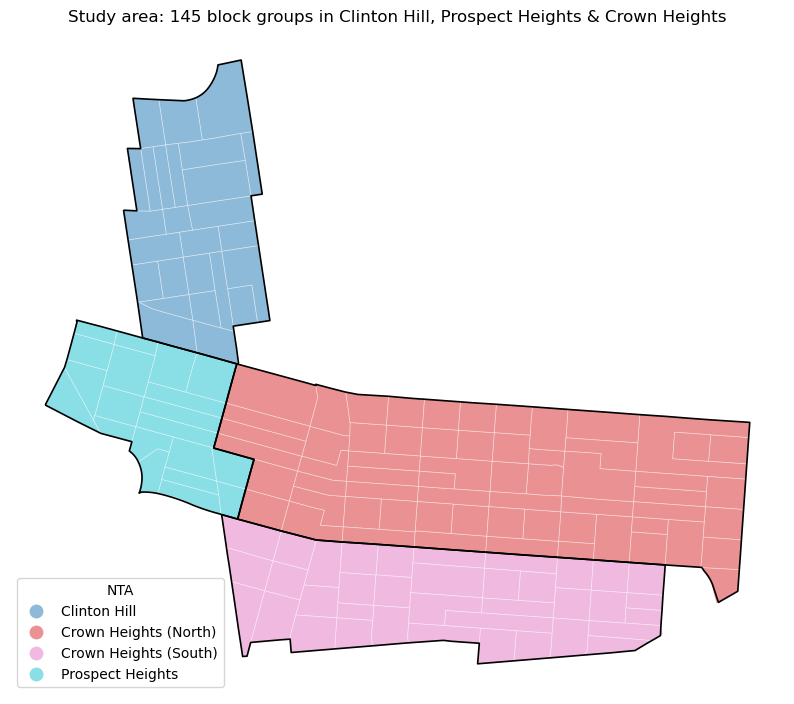

In [6]:
fig, ax = plt.subplots(figsize=(10, 10))
study_bg.plot(ax=ax, column="ntaname", categorical=True, legend=True, alpha=0.5,
              edgecolor="white", linewidth=0.5,
              legend_kwds={"loc": "lower left", "title": "NTA"})
nta.boundary.plot(ax=ax, color="black", linewidth=1.2)
ax.set_title(f"Study area: {len(study_bg)} block groups in {STUDY_NAME}")

## 4. Baseline: population spread evenly across each block group

The simplest assumption is that people are spread evenly over each block group's area. To show what that looks like, we draw **one dot per 10 residents** at random locations inside each block group, using `utils.random_points_in_geom()`.

This baseline puts people in parks, schools, rail yards and on streets, wherever a block group has non-residential land. The lot-level method in the next steps fixes that.

Text(0.5, 1.0, 'Even-spread assumption: 1 dot = 10 residents')

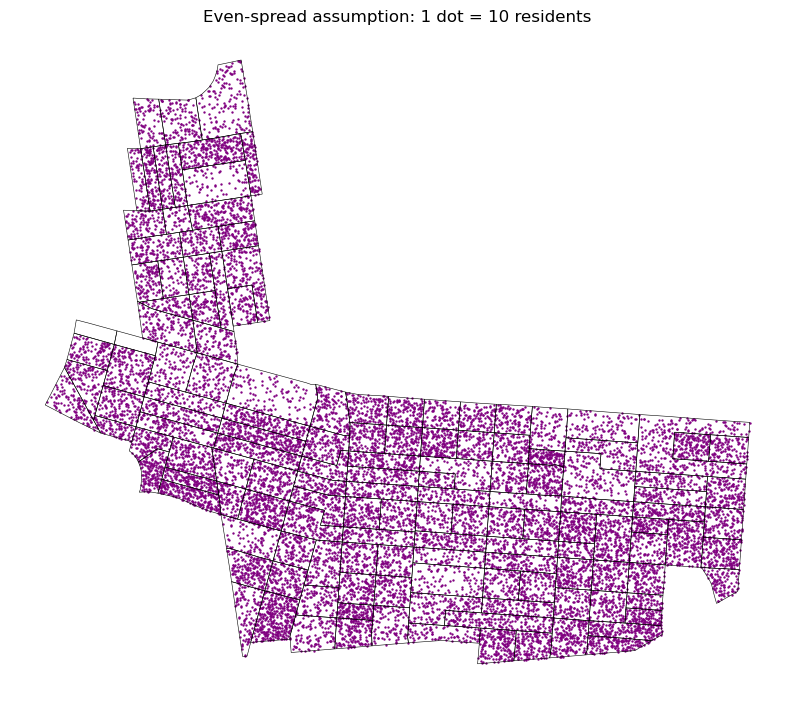

In [7]:
study_bg["pop_points"] = study_bg.apply(
    lambda row: utils.random_points_in_geom(row.geometry, row["pop"] / 10, rng=rng),
    axis=1,
)

ax = study_bg.boundary.plot(color="black", linewidth=0.4, figsize=(10, 10))
study_bg.set_geometry("pop_points").plot(ax=ax, color="purple", markersize=0.5)
ax.set_title("Even-spread assumption: 1 dot = 10 residents")

## 5. MapPLUTO tax lots for the study area

We query the MapPLUTO FeatureServer for lots in the study area's census tracts. `BCT2020` is MapPLUTO's 2020 tract code: a 1-digit borough code (`3` = Brooklyn) plus the 6-digit tract number, e.g. `3020100`.

The service returns at most 2,000 features per request, so the loop pages through results with `resultOffset` until a page comes back short.

Fields kept:
- `BBL`: borough-block-lot ID of the tax lot
- `Address`, `LandUse`: for inspecting results
- `UnitsRes`: number of residential units on the lot
- `BCTCB2020`: 2020 census block (borough + tract + 4-digit block)

In [8]:
PLUTO_URL = "https://services5.arcgis.com/GfwWNkhOj9bNBqoJ/arcgis/rest/services/MAPPLUTO/FeatureServer/0/query"

study_tracts = sorted("3" + study_bg["TRACTCE"].unique())   # "3" = Brooklyn in MapPLUTO
where = "BCT2020 IN (" + ",".join(f"'{t}'" for t in study_tracts) + ")"

all_features, offset = [], 0
while True:
    params = {
        "where": where,
        "outFields": "BBL,Address,LandUse,UnitsRes,BCTCB2020,BCT2020",
        "returnGeometry": "true",
        "outSR": CRS,
        "resultOffset": offset,
        "resultRecordCount": 2000,
        "f": "geojson",
    }
    fc = requests.post(PLUTO_URL, data=params).json()   # POST: the tract list makes a long query
    if "error" in fc:
        raise RuntimeError(fc["error"])
    feats = fc.get("features", [])
    all_features.extend(feats)
    if len(feats) < 2000:
        break
    offset += 2000

pluto = gpd.GeoDataFrame.from_features(all_features, crs=CRS)
pluto["UnitsRes"] = pluto["UnitsRes"].fillna(0)
print(f"Lots downloaded: {len(pluto):,} | residential units: {int(pluto['UnitsRes'].sum()):,}")

Lots downloaded: 13,404 | residential units: 87,104


## 6. Give each lot the same block-group ID as the Census data

`BCTCB2020` looks like `30201001002`: borough `3` + tract `020100` + block `1002`. The **first digit of a census block number is its block group**, so `BCTCB2020[1:8]` is tract + block group.

Tract numbers repeat across boroughs, so we also add the state and county codes. That gives a full 12-digit GEOID that matches the Census data:

`"36"` + county (from the borough digit) + tract + block group, e.g. `360470201001`

In [9]:
b = pluto["BCTCB2020"].astype("string")
pluto["GEOID"] = "36" + b.str[0].map(BORO_TO_COUNTY) + b.str[1:8]

# Safety filter: keep only lots whose block group is in the study area
# (drops lots with a missing or unmatched BCTCB2020)
pluto = pluto[pluto["GEOID"].isin(study_bg["GEOID"])].copy()

print(f"Lots in study block groups: {len(pluto):,}")
print(f"Block groups with at least one lot: {pluto['GEOID'].nunique()} of {len(study_bg)}")

Lots in study block groups: 13,404
Block groups with at least one lot: 145 of 145


## 7. Apportion population to lots by residential units

For each lot:

$$\text{est\_pop\_per\_lot} = \text{block-group population} \times \frac{\text{lot UnitsRes}}{\text{total UnitsRes in the block group}}$$

`groupby(...).transform("sum")` puts each block group's total units on every one of its lots. That handles all lots in a single step instead of filtering the whole table once per lot.

**Check:** the lot estimates should add back up to the study-area population. Anything lost belongs to block groups with no residential units in MapPLUTO.

In [10]:
pluto = pluto.merge(study_bg[["GEOID", "pop", "ntaname"]], on="GEOID", how="left", validate="m:1")

bg_units = pluto.groupby("GEOID")["UnitsRes"].transform("sum")
pluto["est_pop_per_lot"] = np.where(bg_units > 0, pluto["UnitsRes"] / bg_units * pluto["pop"], 0)

allocated = pluto["est_pop_per_lot"].sum()
total = study_bg["pop"].sum()
print(f"Census population:     {total:,}")
print(f"Allocated to lots:     {allocated:,.0f} ({allocated / total:.1%})")
print(f"Lots with residents:   {(pluto['est_pop_per_lot'] > 0).sum():,}")

Census population:     188,027
Allocated to lots:     188,027 (100.0%)
Lots with residents:   12,056


## 8. Map: estimated population per tax lot

Only lots with at least one estimated resident are shown. Colours use natural breaks, so the large apartment buildings stand out against the rowhouse blocks.

Text(0.5, 1.0, 'Estimated population per tax lot, Clinton Hill, Prospect Heights & Crown Heights (2020)')

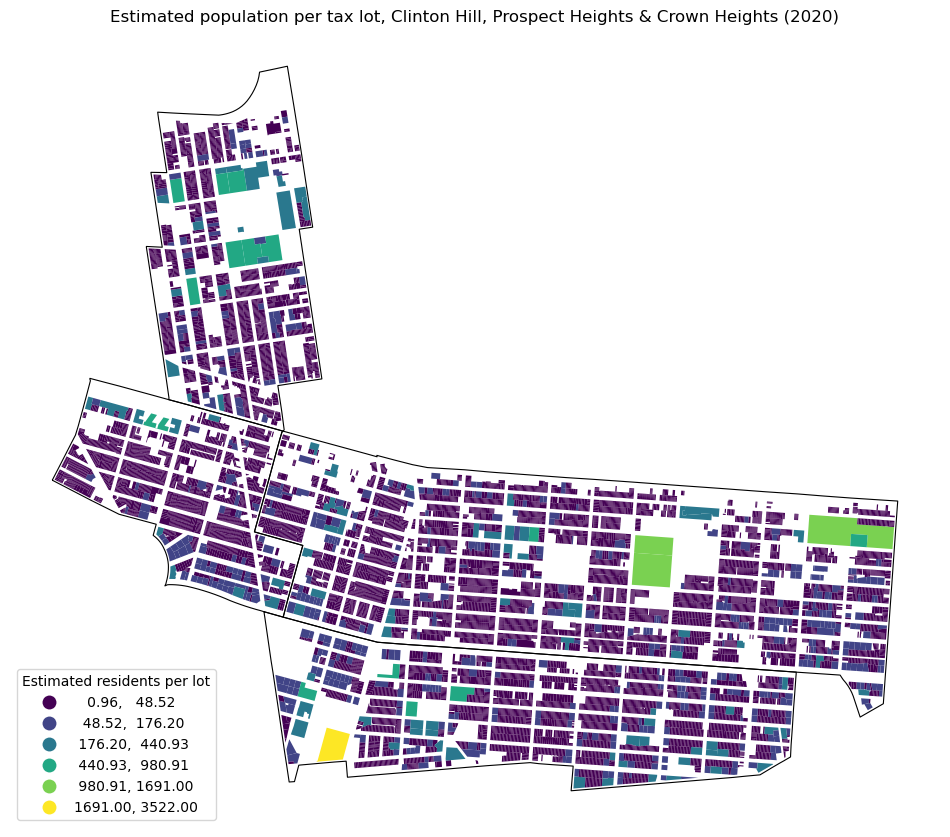

In [11]:
fig, ax = plt.subplots(figsize=(12, 12))
nta.boundary.plot(ax=ax, color="black", linewidth=0.8)
pluto[pluto["est_pop_per_lot"] > 0].plot(
    ax=ax, column="est_pop_per_lot", scheme="naturalbreaks", k=6, cmap="viridis",
    legend=True, legend_kwds={"title": "Estimated residents per lot", "loc": "lower left"},
)
ax.set_title(f"Estimated population per tax lot, {STUDY_NAME} (2020)")

## 9. Map: population dots by tax lot

The same estimates drawn as **one dot per 2 residents**, placed randomly inside each residential lot. Compare this with the even-spread map in step 4: parks, institutions and rail yards are now empty, and dense buildings show up as dense clusters.

Text(0.5, 1.0, 'Apportioned to tax lots by residential units (1 dot = 2 residents)')

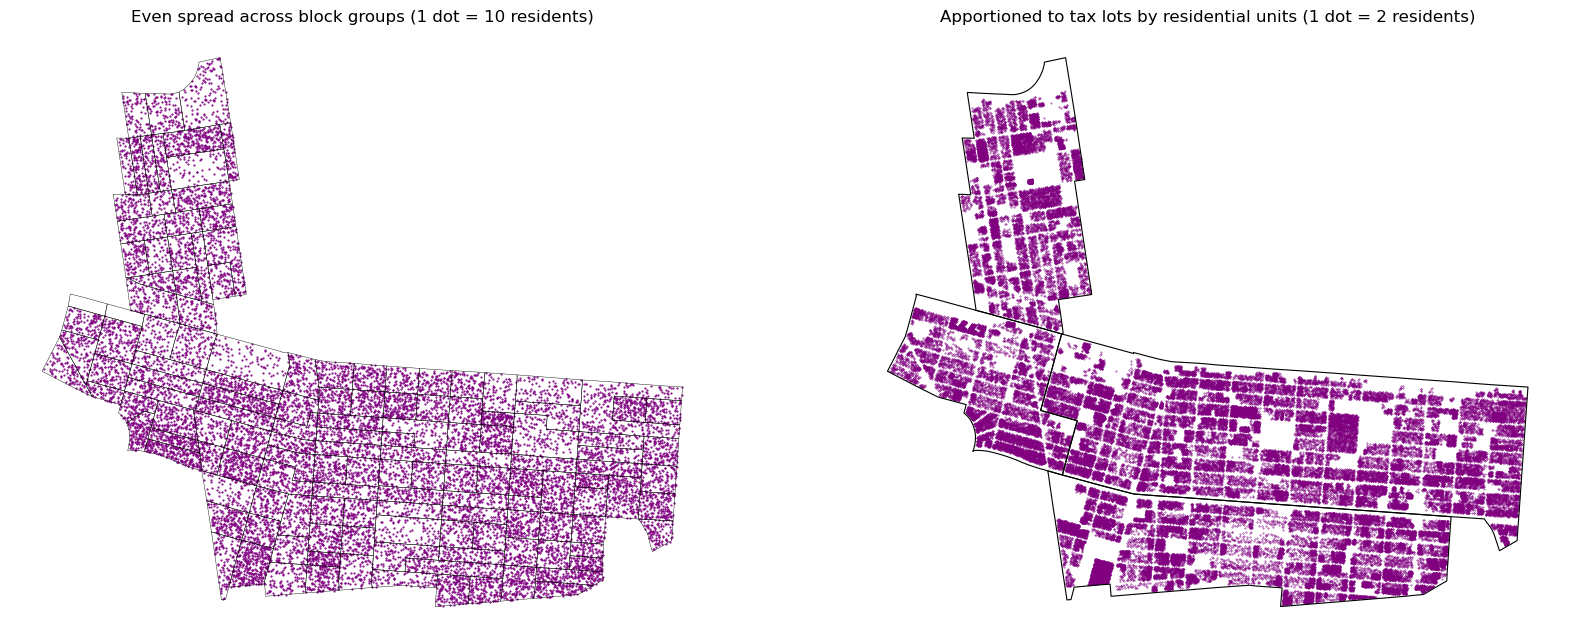

In [12]:
res_lots = pluto[pluto["est_pop_per_lot"] >= 1].copy()
res_lots["pop_points"] = res_lots.apply(
    lambda row: utils.random_points_in_geom(row.geometry, row["est_pop_per_lot"] / 2, rng=rng),
    axis=1,
)

fig, axes = plt.subplots(1, 2, figsize=(20, 10))

study_bg.boundary.plot(ax=axes[0], color="black", linewidth=0.3)
study_bg.set_geometry("pop_points").plot(ax=axes[0], color="purple", markersize=0.3)
axes[0].set_title("Even spread across block groups (1 dot = 10 residents)")

nta.boundary.plot(ax=axes[1], color="black", linewidth=0.8)
res_lots.set_geometry("pop_points").plot(ax=axes[1], color="purple", markersize=0.1)
axes[1].set_title("Apportioned to tax lots by residential units (1 dot = 2 residents)")

## 10. Save the lot-level estimates

Saved as GeoParquet so later notebooks (walksheds, amenity access) can load it directly with `gpd.read_parquet()`.

In [13]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
out_file = OUTPUT_DIR / "lot_population_clinton_prospect_crown_2020.parquet"
pluto[["BBL", "Address", "LandUse", "UnitsRes", "GEOID", "ntaname", "pop", "est_pop_per_lot", "geometry"]].to_parquet(out_file)
print(f"Saved {len(pluto):,} lots to {out_file}")

Saved 13,404 lots to /Users/temp/Documents/GitHub/MappingAffordances/Data_Output/Population/lot_population_clinton_prospect_crown_2020.parquet


## Caveats

- **Assumption:** every residential unit in a block group holds the same number of people. Household size really varies (family-sized units vs. studios, vacant units), so individual lot values are estimates. Totals over larger areas are more reliable than any single lot.
- **Group quarters:** P1 counts everyone, including people in dorms, nursing homes and shelters. Those buildings often have `UnitsRes = 0` in MapPLUTO, so their residents get spread onto ordinary housing in the same block group. College dorms in Clinton Hill are one likely case.
- **Timing:** population is from April 2020; MapPLUTO is the current release. Buildings completed since 2020 have units but no 2020 residents behind them, so they dilute the estimate for older buildings in the same block group.
- **Boundaries:** TIGER block groups and NYC NTAs come from different sources, so lines can differ by a few feet. That's why block groups are assigned to NTAs by an interior point.

---
# Part 2: Every neighborhood in NYC

The same method as Part 1, run for **all 262 NYC Neighborhood Tabulation Areas (NTAs)** at once.

Population is apportioned **once, citywide, at the block-group level**, so each block group's population is shared only among its own lots. Lots are then grouped by neighborhood. Because 2020 NTAs are built from whole census tracts, every block group, and so every lot, falls in exactly one NTA.

**Outputs** go to `Data_Output/Population/<Borough>/`. Each neighborhood gets two files, named by NTA code and name:

| File | Contents |
|---|---|
| `BK0204_Clinton_Hill.parquet` | Every tax lot in the NTA with `UnitsRes`, block-group population and `est_pop_per_lot` (GeoParquet, EPSG:2263) |
| `BK0204_Clinton_Hill.png` | Map of estimated residents per lot (same style as section 8) |

A summary table for all neighborhoods is saved as `Data_Output/Population/nta_population_summary.csv`.

NTAs include parks, cemeteries and airports (`ntatype` other than `0`). They are kept so the set is complete, but most have few or no residents.

## 2.1 Settings

In [14]:
from concurrent.futures import ThreadPoolExecutor
import re

NYC_COUNTIES = list(BORO_TO_COUNTY.values())            # 061, 005, 047, 081, 085
BORO_FOLDERS = {"Manhattan": "Manhattan", "Bronx": "Bronx", "Brooklyn": "Brooklyn",
                "Queens": "Queens", "Staten Island": "Staten_Island"}

# MapPLUTO is ~857k lots; the download is cached here so reruns take seconds.
PLUTO_CACHE = PROJECT / "cache/mappluto_lots_citywide.parquet"
REFRESH_PLUTO = False      # set True to force a fresh download (e.g. new MapPLUTO release)

SAVE_MAPS = True           # set False to write only the parquet files (much faster)

## 2.2 Census population and block groups for all five boroughs

Same steps as sections 1 and 2, without the Brooklyn filter. The P1 download already covers only the five NYC counties.

In [15]:
city_p1 = pd.read_csv(P1_CSV, skiprows=[1], dtype={"GEO_ID": str})
city_p1["GEOID"] = city_p1["GEO_ID"].str[-12:]
city_p1["pop"] = city_p1["P1_001N"].astype(int)
city_p1 = city_p1[city_p1["GEOID"].str[2:5].isin(NYC_COUNTIES)]

county_list = ",".join(f"'{c}'" for c in NYC_COUNTIES)
city_bg = gpd.read_file(
    "https://www2.census.gov/geo/tiger/TIGER2020/BG/tl_2020_36_bg.zip",
    where=f"COUNTYFP IN ({county_list})",
).to_crs(CRS)
city_bg = city_bg[["GEOID", "geometry"]].merge(
    city_p1[["GEOID", "pop"]], on="GEOID", how="left", validate="1:1"
)

print(f"NYC block groups: {len(city_bg):,} | missing population: {city_bg['pop'].isna().sum()}")
print(f"NYC population (2020 Census): {city_bg['pop'].sum():,.0f}")

NYC block groups: 6,807 | missing population: 0
NYC population (2020 Census): 8,804,190


## 2.3 Assign every block group to an NTA

Each block group is assigned to the NTA it overlaps **most by area**.

Part 1 used an interior point instead. That doesn't work citywide: NYC's NTA boundaries stop at the shoreline, but Census block groups extend into the water, so a coastal block group's interior point can land in a river and match nothing. Largest overlap avoids this, and it also handles the small line differences between Census and NYC boundaries.

Block groups left unassigned are water-only areas; the check below shows how many people they hold.

In [16]:
r = requests.get("https://data.cityofnewyork.us/resource/9nt8-h7nd.geojson", params={"$limit": 1000})
r.raise_for_status()
city_nta = gpd.GeoDataFrame.from_features(r.json(), crs=4326).to_crs(CRS)
city_nta = city_nta[["nta2020", "ntaname", "boroname", "ntatype", "geometry"]]

# Cut every block group by the NTAs, then keep the piece with the largest area
pieces = gpd.overlay(city_bg[["GEOID", "geometry"]], city_nta, how="intersection", keep_geom_type=True)
pieces["overlap_area"] = pieces.area
bg_nta = (
    pieces.sort_values("overlap_area", ascending=False)
    .drop_duplicates("GEOID")[["GEOID", "nta2020", "ntaname", "boroname", "ntatype"]]
)

city_bg = city_bg.merge(bg_nta, on="GEOID", how="left", validate="1:1")
unassigned = city_bg[city_bg["nta2020"].isna()]

print(f"NTAs: {len(city_nta)}")
print(f"Block groups assigned to an NTA: {city_bg['nta2020'].notna().sum():,} of {len(city_bg):,}")
print(f"Unassigned (water) block groups: {len(unassigned)} (population {unassigned['pop'].sum():,.0f})")

NTAs: 262
Block groups assigned to an NTA: 6,774 of 6,807
Unassigned (water) block groups: 33 (population 31)


## 2.4 Download MapPLUTO for the whole city

The FeatureServer returns at most 2,000 lots per request, so the city takes about 430 requests. They're sent 8 at a time, in a fixed `OBJECTID` order so pages don't overlap or skip lots. `geometryPrecision=1` rounds coordinates to 0.1 ft, which cuts the download by about a third with no visible effect.

The result is saved to `cache/`. Later runs load that file instead of downloading again, unless `REFRESH_PLUTO = True`.

In [17]:
def fetch_pluto_page(offset):
    params = {
        "where": "1=1",
        "outFields": "BBL,Borough,Address,LandUse,UnitsRes,BCTCB2020",
        "returnGeometry": "true",
        "outSR": CRS,
        "geometryPrecision": 1,
        "orderByFields": "OBJECTID",
        "resultOffset": offset,
        "resultRecordCount": 2000,
        "f": "geojson",
    }
    for attempt in range(3):          # retry occasional network hiccups
        try:
            fc = requests.post(PLUTO_URL, data=params, timeout=120).json()
            if "error" in fc:
                raise RuntimeError(fc["error"])
            return fc["features"]
        except Exception:
            if attempt == 2:
                raise


if PLUTO_CACHE.exists() and not REFRESH_PLUTO:
    city_lots = gpd.read_parquet(PLUTO_CACHE)
    print(f"Loaded {len(city_lots):,} lots from cache ({PLUTO_CACHE.name})")
else:
    n_lots = requests.get(PLUTO_URL, params={"where": "1=1", "returnCountOnly": "true", "f": "json"}).json()["count"]
    with ThreadPoolExecutor(max_workers=8) as pool:
        pages = list(pool.map(fetch_pluto_page, range(0, n_lots, 2000)))
    city_lots = gpd.GeoDataFrame.from_features([f for page in pages for f in page], crs=CRS)
    assert len(city_lots) == n_lots, f"expected {n_lots:,} lots, got {len(city_lots):,}"
    assert city_lots["BBL"].is_unique
    PLUTO_CACHE.parent.mkdir(parents=True, exist_ok=True)
    city_lots.to_parquet(PLUTO_CACHE)
    print(f"Downloaded {len(city_lots):,} lots and cached to {PLUTO_CACHE}")

city_lots["UnitsRes"] = city_lots["UnitsRes"].fillna(0)

Loaded 856,687 lots from cache (mappluto_lots_citywide.parquet)


## 2.5 Apportion population to lots, citywide

**Step A** uses the same formula as section 7: each block group's population is shared among its own lots in proportion to `UnitsRes`.

**Step B is a fallback for large complexes.** MapPLUTO records one census block per tax lot. A superblock development such as Stuy Town, Co-op City or a large NYCHA campus can span several block groups but is filed under just one. The other block groups then appear to have people but no housing, and step A can't place those residents.

For those block groups, step B spreads the population onto the residential lots that physically overlap the block group. Each lot is weighted by its units × the share of the lot's area inside the block group.

What's left after step B is population with genuinely no residential units: group quarters such as jails, dorms and shelters (listed below the next cell).

In [18]:
b = city_lots["BCTCB2020"].astype("string")
city_lots["GEOID"] = "36" + b.str[0].map(BORO_TO_COUNTY) + b.str[1:8]

no_block = city_lots["GEOID"].isna()
print(f"Lots without a census block: {no_block.sum():,} (residential units on them: {int(city_lots.loc[no_block, 'UnitsRes'].sum()):,})")

city_lots = city_lots.merge(
    city_bg[["GEOID", "pop", "nta2020", "ntaname", "boroname", "ntatype"]],
    on="GEOID", how="left", validate="m:1",
)

# --- Step A: share each block group's population among its own lots by units ---
bg_units = city_lots.groupby("GEOID")["UnitsRes"].transform("sum")
city_lots["est_pop_per_lot"] = np.where(bg_units > 0, city_lots["UnitsRes"] / bg_units * city_lots["pop"], 0)
city_lots["est_pop_per_lot"] = city_lots["est_pop_per_lot"].fillna(0)

units_by_bg = city_lots.groupby("GEOID")["UnitsRes"].sum()
city_bg["units"] = city_bg["GEOID"].map(units_by_bg).fillna(0)
stranded = city_bg[(city_bg["units"] == 0) & (city_bg["pop"] > 0)]
step_a = city_lots["est_pop_per_lot"].sum()

# --- Step B: place stranded block groups' population on residential lots that overlap them ---
res_lots = city_lots.loc[city_lots["UnitsRes"] > 0, ["UnitsRes", "geometry"]].copy()
res_lots["lot_area"] = res_lots.area
res_lots["lot_index"] = res_lots.index

overlap = gpd.overlay(res_lots, stranded[["GEOID", "pop", "geometry"]], how="intersection", keep_geom_type=True)
overlap["weight"] = overlap["UnitsRes"] * overlap.area / overlap["lot_area"]
overlap = overlap[overlap["weight"] > 0]
overlap["added_pop"] = overlap["pop"] * overlap["weight"] / overlap.groupby("GEOID")["weight"].transform("sum")

added = overlap.groupby("lot_index")["added_pop"].sum()
city_lots["pop_from_overlap"] = 0.0
city_lots.loc[added.index, "pop_from_overlap"] = added
city_lots["est_pop_per_lot"] += city_lots["pop_from_overlap"]

unplaced = stranded[~stranded["GEOID"].isin(overlap["GEOID"])]

total = city_bg["pop"].sum()
allocated = city_lots["est_pop_per_lot"].sum()
print(f"NYC population:            {total:,.0f}")
print(f"Step A (own lots):         {step_a:,.0f}")
print(f"Step B (overlapping lots): {added.sum():,.0f} from {overlap['GEOID'].nunique()} block groups")
print(f"Allocated to lots:         {allocated:,.0f} ({allocated / total:.2%})")
print(f"Not placed (group quarters / water): {total - allocated:,.0f}")

Lots without a census block: 23 (residential units on them: 2)


NYC population:            8,804,190
Step A (own lots):         8,636,929
Step B (overlapping lots): 153,011 from 130 block groups
Allocated to lots:         8,789,940 (99.84%)
Not placed (group quarters / water): 14,250


Block groups whose population still couldn't be placed: no residential lots inside them at all. These are group quarters (jails, dorms, shelters, hospitals).

In [19]:
unplaced.sort_values("pop", ascending=False)[["GEOID", "ntaname", "boroname", "pop"]].head(10)

,GEOID,ntaname,boroname,pop
4964,360050001001,Rikers Island,Bronx,3772
878,360470018012,Sunset Park (West),Brooklyn,2562
4695,360610203002,Morningside Heights,Manhattan,1981
6618,360610240002,Randall's Island,Manhattan,1300
6176,360610062001,Murray Hill-Kips Bay,Manhattan,953
860,360471208022,East New York-City Line,Brooklyn,768
5603,360470340002,Coney Island-Sea Gate,Brooklyn,571
1744,360810306001,Springfield Gardens (South)-Brookville,Queens,416
6472,360810199012,Sunnyside,Queens,225
4611,360610143001,Central Park,Manhattan,129


## 2.6 Summary by neighborhood

- `census_pop`: the 2020 count in the NTA's block groups.
- `allocated_pop`: how much population ended up on the NTA's lots.

The two differ where population couldn't be placed (group quarters). They can also differ slightly where step B moved a block group's residents onto an overlapping lot in a neighbouring NTA.

In [20]:
nta_summary = (
    city_bg.dropna(subset=["nta2020"])
    .groupby(["boroname", "nta2020", "ntaname", "ntatype"], as_index=False)
    .agg(block_groups=("GEOID", "size"), census_pop=("pop", "sum"))
    .merge(
        city_lots.dropna(subset=["nta2020"])
        .groupby("nta2020", as_index=False)
        .agg(lots=("BBL", "size"), res_units=("UnitsRes", "sum"), allocated_pop=("est_pop_per_lot", "sum")),
        on="nta2020", how="left",
    )
    .fillna({"lots": 0, "res_units": 0, "allocated_pop": 0})
    .astype({"lots": int, "res_units": int, "census_pop": int})
    .round({"allocated_pop": 0})
    .sort_values(["boroname", "nta2020"])
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
nta_summary.to_csv(OUTPUT_DIR / "nta_population_summary.csv", index=False)

print(nta_summary.groupby("boroname")[["census_pop", "allocated_pop"]].sum().astype(int))
nta_summary.sort_values("census_pop", ascending=False).head(10)

               census_pop  allocated_pop
boroname                                
Bronx             1481254        1477340
Brooklyn          2736074        2731902
Manhattan         1685620        1680496
Queens            2405464        2404511
Staten Island      495747         495691


,boroname,nta2020,ntaname,ntatype,block_groups,census_pop,lots,res_units,allocated_pop
173,Queens,QN0401,Elmhurst,0,60,107864,7380,34540,107864.0
85,Brooklyn,BK1101,Bensonhurst,0,76,104934,11165,34664,104934.0
170,Queens,QN0301,Jackson Heights,0,62,101848,6750,35148,101848.0
138,Manhattan,MN0702,Upper West Side (Central),0,77,101767,2591,57312,101733.0
89,Brooklyn,BK1202,Borough Park,0,65,93905,8807,25574,93905.0
111,Brooklyn,BK1803,Canarsie,0,55,89932,12750,27248,89931.0
59,Brooklyn,BK0301,Bedford-Stuyvesant (West),0,61,89189,7488,36643,89189.0
184,Queens,QN0602,Forest Hills,0,70,88965,7543,43683,88965.0
81,Brooklyn,BK1001,Bay Ridge,0,78,86779,10145,37468,86779.0
140,Manhattan,MN0801,Upper East Side-Lenox Hill-Roosevelt Island,0,71,85527,1357,60290,85527.0


## 2.7 Write one file (and map) per neighborhood

For each NTA, the lots are written to `Data_Output/Population/<Borough>/<NTA code>_<name>.parquet`, and a map like section 8 is saved next to it as a `.png`. NTAs with no residents get a parquet file but no map, since there would be nothing to show.

With maps on, this takes a few minutes; `plt.close` frees each figure so memory doesn't build up.

In [21]:
def safe_name(name):
    # "Mariner's Harbor-Arlington" -> "Mariners_Harbor-Arlington"
    return re.sub(r"[^A-Za-z0-9\-]+", "_", name.replace("'", "")).strip("_")


EXPORT_COLS = ["BBL", "Address", "LandUse", "UnitsRes", "GEOID", "nta2020", "ntaname", "boroname",
               "pop", "est_pop_per_lot", "geometry"]
lots_by_nta = dict(tuple(city_lots.dropna(subset=["nta2020"]).groupby("nta2020")))

written = []
for nta_row in city_nta.sort_values("nta2020").itertuples():
    folder = OUTPUT_DIR / BORO_FOLDERS[nta_row.boroname]
    folder.mkdir(parents=True, exist_ok=True)
    stem = f"{nta_row.nta2020}_{safe_name(nta_row.ntaname)}"

    lots = lots_by_nta.get(nta_row.nta2020, city_lots.iloc[0:0])[EXPORT_COLS]
    lots.to_parquet(folder / f"{stem}.parquet")

    residential = lots[lots["est_pop_per_lot"] > 0]
    if SAVE_MAPS and len(residential) > 0:
        fig, ax = plt.subplots(figsize=(10, 10))
        gpd.GeoSeries([nta_row.geometry], crs=CRS).boundary.plot(ax=ax, color="black", linewidth=0.8)
        if residential["est_pop_per_lot"].nunique() > 6:
            residential.plot(ax=ax, column="est_pop_per_lot", cmap="viridis", scheme="naturalbreaks", k=6,
                             legend=True, legend_kwds={"title": "Estimated residents per lot", "loc": "lower left"})
        else:  # too few distinct values for natural breaks (tiny or park NTAs)
            residential.plot(ax=ax, column="est_pop_per_lot", cmap="viridis", legend=True)
        ax.set_title(f"{nta_row.ntaname} ({nta_row.nta2020}): estimated population per tax lot, 2020\n"
                     f"{residential['est_pop_per_lot'].sum():,.0f} residents on {len(residential):,} lots")
        fig.savefig(folder / f"{stem}.png", dpi=120, bbox_inches="tight")
        plt.close(fig)

    written.append({"boro": nta_row.boroname, "nta2020": nta_row.nta2020, "lots": len(lots)})

written = pd.DataFrame(written)
print(f"Wrote {len(written)} neighborhoods:")
print(written.groupby("boro").size().to_string())

Wrote 262 neighborhoods:
boro
Bronx            50
Brooklyn         69
Manhattan        38
Queens           82
Staten Island    23


## 2.8 Citywide overview

Population by neighborhood, as a check that the full run looks right. NTAs with no residents (parks, cemeteries, airports) are shown in grey.

Text(0.5, 1.0, 'Estimated residents by neighborhood (NTA), 2020')

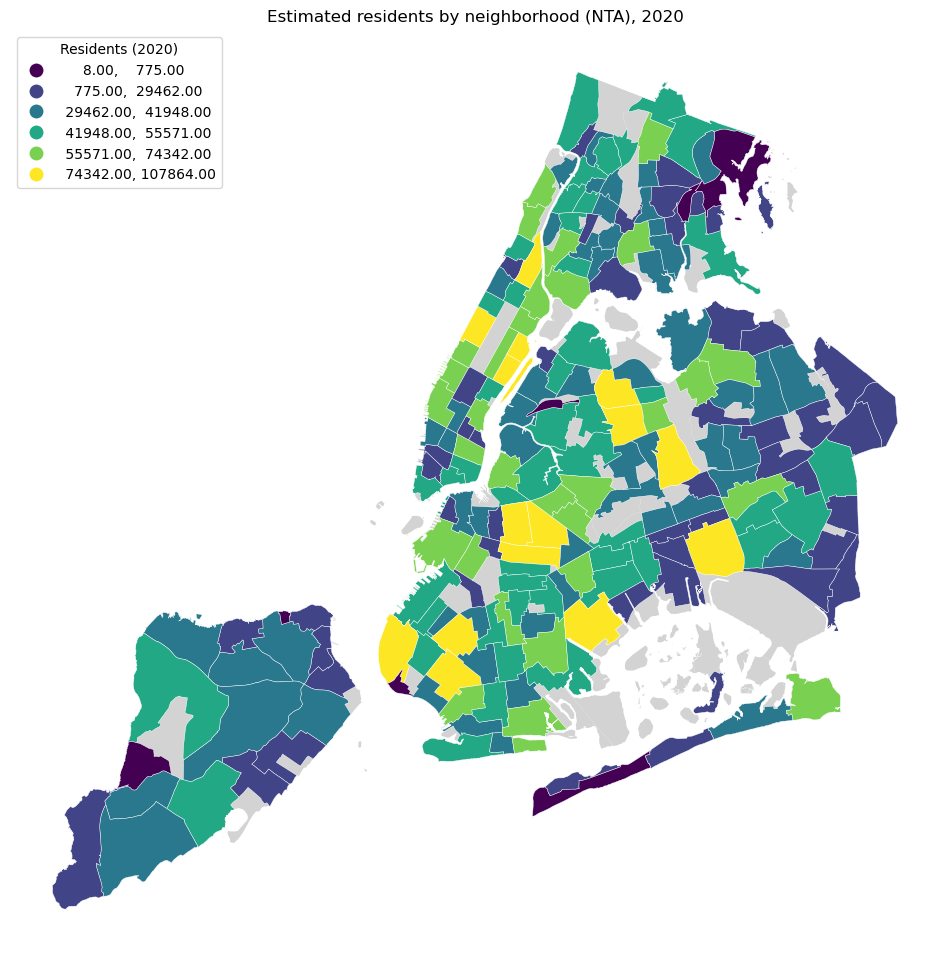

In [22]:
overview = city_nta.merge(nta_summary[["nta2020", "allocated_pop"]], on="nta2020", how="left")

fig, ax = plt.subplots(figsize=(12, 12))
overview[overview["allocated_pop"] == 0].plot(ax=ax, color="lightgrey")
overview[overview["allocated_pop"] > 0].plot(
    ax=ax, column="allocated_pop", cmap="viridis", scheme="naturalbreaks", k=6,
    edgecolor="white", linewidth=0.3,
    legend=True, legend_kwds={"title": "Residents (2020)", "loc": "upper left"},
)
ax.set_title("Estimated residents by neighborhood (NTA), 2020")